# 05 — Validación: ¿se puede predecir el aumento del conteo sin el motivo?

## Qué contesta este cuaderno

**Origen de la pregunta (2026-09-28).** El superior del propietario sostiene que el motivo escrito
en la nota de triage no hace falta. Las notas las escriben enfermeras y están sujetas a
interpretación. Bastaría con **conteo + fecha** enfrentados a factores externos: clima, salud,
eventos y desastres. Aquí se mide si los datos le dan la razón. No es una decisión: es la medición
que la sostiene.

Cinco preguntas, en orden:
1. ¿Qué traen de verdad los calendarios externos que había?
2. ¿Cuánto del conteo queda por explicar después del calendario, y cuánto es azar irreducible?
3. ¿Qué variables externas se asocian con el conteo, en el total y en los niños?
4. ¿Alguna **mejora el pronóstico** a una semana, fuera de muestra?
5. ¿Hay potencia para ver el efecto que se busca?

**Este cuaderno es la conversión de `notebooks/05_validacion_sin_motivo.py`**, que se conserva
intacto. Tiene dos añadidos, que van al final:
- **«Corrección del 2026-09-29»**: el tratamiento de la caída del registro de marzo de 2024, con
  las cifras de antes y de después.
- **«Lo que se supo después»**: el cuaderno 07 matizó su conclusión principal.

*(Añadido el 2026-09-29, tarde.)* El clima se corrigió después de escribir este cuaderno: el
pluviómetro de La Nubia reportaba cero de octubre de 2025 a julio de 2026 y ahora esos días se
tratan como sin pluviómetro (cuaderno 03, sección 3.1). El cuaderno se volvió a ejecutar con el clima
corregido. **Cada lectura cuya cifra se movió lleva un recuadro «Corrección del 2026-09-29 (clima
corregido)»** con la cifra de antes y la de después; el texto original se deja como estaba.

## Diseño, fijado antes de mirar resultados

Escrito en el docstring del script el 2026-09-28, antes de correrlo:

- **Ventana de análisis:** 2022-03-01 a 2026-09-20. Fuera de COVID y de ómicron; el último día de la
  serie está incompleto.
- **Semana:** de lunes a domingo. Se etiqueta con el domingo en que termina.
- **Control de calendario:**
  - día de la semana, festivo, puente, víspera y día después de festivo;
  - quincena, vacaciones escolares, Semana Santa, temporada de Navidad y de fin de año, regreso a
    clases;
  - efecto fijo de año y un **escalón el 2025-11-01**, la «deriva administrativa» medida el
    2026-09-22.
  - **Sin mes del año**: la estacionalidad es parte de lo que se quiere explicar.
- **Anomalías de clima:** contra la climatología del mismo mes (2020-2026).
- **Ruptura seca → lluvia (semanal):** z de lluvia de la semana ≥ +0,5 y media de las 3 semanas
  previas ≤ −0,5.
- **Enfriamiento brusco (semanal):** z de temperatura de la semana menos la media de las 3 previas
  ≤ −1.
- **Indicador pediátrico:** residuo (log) de 0-14 años de la semana anterior.

Las dos variables de transición se definieron aquí antes de correr, pero **no se preregistraron en
`patrones/datos/variables.csv`**: todo lo de este cuaderno es exploratorio.

## De dónde salen los datos

Solo archivos agregados del repositorio; ningún texto, ningún identificador, ninguna conexión a
la base. De dónde sale cada fuente externa, con su entidad y su URL: cuaderno 03.

| Dato | Archivo | Fuente |
|---|---|---|
| Triage diario del SES | `salidas/triage_diario.parquet` | base del hospital (`DIM_TRIAGE`), agregada por día |
| Triage por banda de edad (0-4, 5-14, 15-44, 45-64, 65+) | `salidas/triage_edad.parquet` | la misma base, agregada |
| Triage por nivel: se usan los niveles con «G», que el script trata como obstétricos | `salidas/triage_nivel.parquet` | la misma base, agregada |
| Festivos, puentes, vacaciones | `calendarios/calendario_Colombia.csv` | festivos de ley y reglas propias |
| Clima diario | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR La Nubia, Open-Meteo, NASA POWER |
| Ventanas de vigilancia, ENSO, volcán | `calendarios/vigilancia_salud_manizales_caldas.csv` | calendario manual |
| Eventos y desastres | `calendarios/eventos_manizales_2020_2026.csv`, `desastres_manizales_2020_2026.csv` | calendarios manuales |

**Importante:** este cuaderno usa los calendarios **manuales** que existían el 2026-09-28 por la
mañana. Las series reales del SIVIGILA y de MinDefensa se integraron después, precisamente por lo
que se midió aquí.

In [1]:
import sys, pathlib, warnings, subprocess, re
from math import erf, sqrt
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
    "ytick.color": TINTA2, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "font.size": 10, "legend.frameon": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

INI, FIN = "2022-03-01", "2026-09-20"          # fuera de COVID y omicron; el ultimo dia de la serie esta incompleto
COVID = ("2020-03-15", "2022-02-28")
dias = pd.date_range("2020-01-01", FIN)
pct = lambda z: (np.exp(z) - 1) * 100
DESPUES = {}                                    # cifras de este cuaderno para el recuadro de correccion

d = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet")
tot = d.set_index(pd.to_datetime(d["dia"]))["triages"].astype(float).reindex(dias)   # dia sin filas = NULO
e = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet"); e["dia"] = pd.to_datetime(e["dia"])
ed = e.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)  # en un subgrupo, 0 es 0
ped = ed[[c for c in ed.columns if c.startswith("0-") or c.startswith("5-")]].sum(axis=1)
b04 = ed[[c for c in ed.columns if c.startswith("0-")]].sum(axis=1)
nv = pd.read_parquet(RAIZ / "salidas/triage_nivel.parquet"); nv["dia"] = pd.to_datetime(nv["dia"])
obst = nv[nv["nivel"].astype(str).str.contains("G")].groupby("dia")["n"].sum().reindex(dias).fillna(0)
D = pd.DataFrame({"total": tot, "ped": ped, "b04": b04, "obst": obst})

CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad",
       "es_temporada_fin_anio", "es_regreso_colegio"]
k = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
k = k[CAL + ["dia_semana"]].apply(pd.to_numeric, errors="coerce").fillna(0)
c = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
c = c[["precip_consenso_mm", "temp_media_consenso", "humedad_consenso", "temp_min_consenso", "precip_con_estacion"]]
D = D.join(k).join(c)
print(f"{len(D)} días, {D.index.min():%Y-%m-%d} a {D.index.max():%Y-%m-%d}; bandas de edad: {list(ed.columns)}")

2455 días, 2020-01-01 a 2026-09-20; bandas de edad: ['0-4', '15-44', '45-64', '5-14', '65-+', 'sin edad']


---
# 0. Las caídas del registro

**Regla del cuaderno 06, que vale para todo el proyecto:**
- Un día **sin filas** en el total es una caída del registro, no cero pacientes: un servicio de
  urgencias no cierra. Queda **nulo**.
- Un día con **menos del 40 % de lo esperado** por el calendario y el año, fuera de COVID, es una
  caída parcial y se **excluye**.
- En los subgrupos (una banda de edad), un día sin filas sí puede ser cero. Pero en un día caído el
  subgrupo también queda nulo.

El script original no aplicaba esta regla. Qué cambia por eso está en «Corrección del 2026-09-29».

días sin ninguna fila: ['2024-03-19', '2024-03-20']
días con < 40 % de lo esperado: {'2024-03-21': '40 triages, esperados 232'}


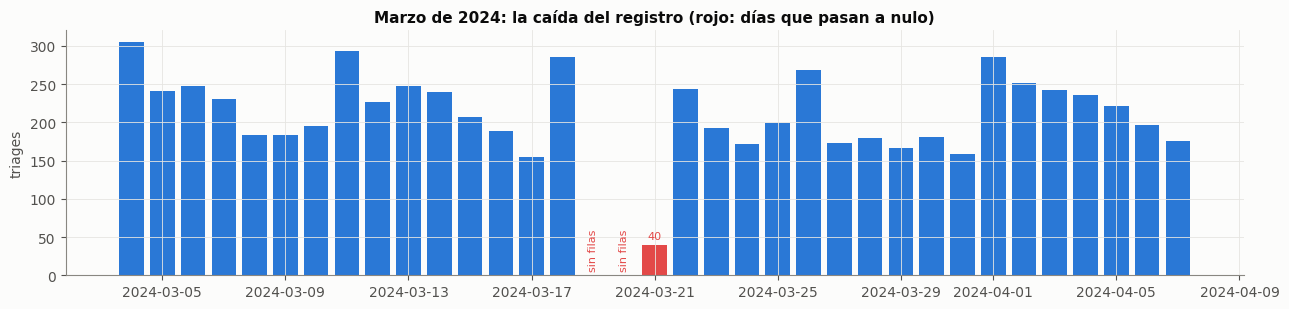

In [2]:
# Caidas del registro (regla del cuaderno 06): un dia SIN filas es nulo, no cero; un dia con menos del
# 40 % de lo esperado por el calendario y el anio, fuera de COVID, es una caida parcial y se excluye.
Z0 = pd.concat([pd.get_dummies(D["dia_semana"].astype(int), prefix="d", drop_first=True).astype(float), D[CAL],
                pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)], axis=1)
Z0.insert(0, "c", 1.0)
fuera_covid = ~dias.to_series().between(*COVID).values
ok0 = fuera_covid & D.total.notna().values
b0, *_ = np.linalg.lstsq(Z0.values[ok0], np.log(D.total.values[ok0]), rcond=None)
res0 = np.log(D.total) - Z0.values @ b0
sin_filas = D.total.isna()
parcial = (res0 < np.log(.4)) & fuera_covid
print("días sin ninguna fila:", [f"{x:%Y-%m-%d}" for x in D.index[sin_filas]])
print("días con < 40 % de lo esperado:", {f"{x:%Y-%m-%d}": f"{int(D.total[x])} triages, esperados {np.exp(np.log(D.total[x]) - res0[x]):.0f}"
                                          for x in D.index[parcial]})
caido = sin_filas | parcial
D.loc[caido, ["total", "ped", "b04", "obst"]] = np.nan
D["adult"] = D["total"] - D["ped"]
D["adult_noobst"] = D["adult"] - D["obst"]

v = D.loc["2024-03-04":"2024-04-07", "total"]
orig = tot.loc[v.index]
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(orig.index, orig.fillna(0), color=[ROJO if caido[x] else AZUL for x in orig.index], width=.8)
for x in orig.index[caido.loc[orig.index]]:
    ax.text(x, (orig.fillna(0)[x]) + 5, "sin filas" if sin_filas[x] else f"{int(orig[x])}", ha="center", va="bottom", fontsize=8, color=ROJO, rotation=90 if sin_filas[x] else 0)
ax.set_ylabel("triages"); ax.set_title("Marzo de 2024: la caída del registro (rojo: días que pasan a nulo)")
plt.tight_layout(); plt.show()

## Lectura

- **El 19 y el 20 de marzo de 2024 no tienen ninguna fila.** El 21 tiene **40 triages, contra 232
  esperados**. Los tres quedan nulos.
- La semana que los contiene (termina el 2024-03-24) queda con el desenlace nulo. No se borra: así
  los rezagos y las medias móviles no «saltan» por encima del hueco.

---
# 1. Qué traen los calendarios externos

Antes de medir un efecto, se mira la variable. La pregunta: **¿las ventanas de vigilancia dicen algo
que el mes del año no diga ya?** Se mide con el R² de cada bandera diaria explicada solo por 12
indicadores de mes.

vigilancia: 321 filas; ventana_estacional (misma fecha cada año): 216 (67%)
  por ámbito: {'nacional': 192, 'caldas': 89, 'manizales': 40}
  con número de casos: 28 | de Manizales con casos: 6
eventos: 99 filas; categorías: {'religioso': 26, 'civico': 22, 'musical': 10, 'feria': 7, 'taurino': 7, 'teatro': 7, 'literario': 7, 'deportivo': 7, 'emergencia': 3, 'academico': 2, 'universitario': 1}
desastres: 17 filas; calidad: {'confirmado': 9, 'pendiente_verificacion': 4, 'fecha_aproximada': 2, 'confirmado_cifras_en_actualizacion': 2}
días por año con El Niño / La Niña: {'nino': {2022: 0, 2023: 214, 2024: 152, 2025: 0, 2026: 112}, 'nina': {2022: 153, 2023: 59, 2024: 31, 2025: 120, 2026: 0}}
  ira_ventana: R2 explicado solo por el mes del año = 0.926
  vsr_ventana: R2 explicado solo por el mes del año = 1.000
  flu_ventana: R2 explicado solo por el mes del año = 1.000
  dengue_ventana: R2 explicado solo por el mes del año = 0.750


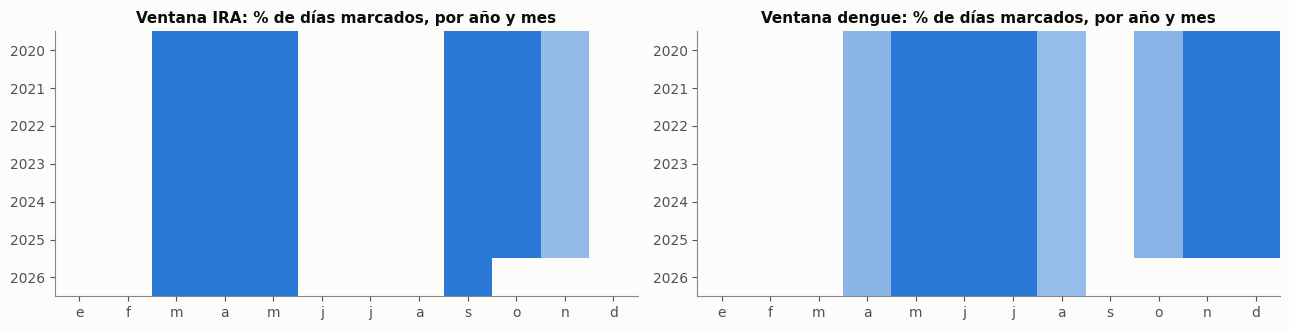

In [3]:
def banderas(df, filtro, ini="fecha_inicio", fin="fecha_fin"):
    s = pd.Series(0.0, index=D.index)
    for _, r in df[filtro].iterrows():
        a = pd.to_datetime(r[ini], errors="coerce"); b = pd.to_datetime(r[fin], errors="coerce")
        if pd.isna(a): continue
        if pd.isna(b): b = a
        s.loc[a:b] = 1
    return s

v = pd.read_csv(RAIZ / "calendarios/vigilancia_salud_manizales_caldas.csv")
ev = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
de = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")
print(f"vigilancia: {len(v)} filas; ventana_estacional (misma fecha cada año): "
      f"{(v.estado == 'ventana_estacional').sum()} ({(v.estado == 'ventana_estacional').mean():.0%})")
print("  por ámbito:", v.ambito_territorial.value_counts().to_dict())
print("  con número de casos:", v.casos.notna().sum(), "| de Manizales con casos:",
      ((v.ambito_territorial == "manizales") & v.casos.notna()).sum())
print(f"eventos: {len(ev)} filas; categorías:", ev.categoria.value_counts().to_dict())
print(f"desastres: {len(de)} filas; calidad:", de.calidad_dato.value_counts().to_dict())

X = pd.DataFrame(index=D.index)
X["ira_ventana"] = banderas(v, (v.subcategoria == "temporada_IRA") & (v.estado == "ventana_estacional"))
X["vsr_ventana"] = banderas(v, (v.subcategoria == "vsr"))
X["flu_ventana"] = banderas(v, (v.subcategoria == "influenza") & (v.estado == "ventana_estacional"))
X["dengue_ventana"] = banderas(v, (v.subcategoria == "dengue") & (v.estado == "ventana_estacional"))
X["nino"] = banderas(v, v.subcategoria == "el_nino")
X["nina"] = banderas(v, v.subcategoria == "la_nina")
X["volcan_naranja"] = banderas(v, v.nombre_evento.str.contains("Naranja", case=False, na=False) |
                               v.descripcion.str.contains("alerta naranja", case=False, na=False) &
                               (v.subcategoria == "actividad_volcanica"))
X["ceniza"] = banderas(v, v.subcategoria == "ceniza_volcanica")
evm = ev[(ev.municipio == "Manizales") & ev.estado.isin(["realizado", "hibrido"])]
X["evento"] = banderas(evm, slice(None))
X["feria"] = banderas(evm, evm.nombre_evento.str.contains("Feria de Manizales"))
X["desastre"] = banderas(de, de.ambito.isin(["municipal", "institucional"]) & (de.calidad_dato != "pendiente_verificacion") &
                         (pd.to_datetime(de.fecha_fin) - pd.to_datetime(de.fecha_inicio)).dt.days.le(7))
X["terremoto"] = 0.0; X.loc["2026-08-10":"2026-08-23", "terremoto"] = 1
D = D.join(X)
print("días por año con El Niño / La Niña:", D.loc[INI:FIN, ["nino", "nina"]].groupby(D.loc[INI:FIN].index.year).sum().astype(int).to_dict())

m = pd.get_dummies(D.index.month).astype(float).values
for col in ["ira_ventana", "vsr_ventana", "flu_ventana", "dengue_ventana"]:
    y = D[col].values
    beta, *_ = np.linalg.lstsq(m, y, rcond=None)
    print(f"  {col}: R2 explicado solo por el mes del año = {1 - ((y - m @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
cmap = LinearSegmentedColormap.from_list("s", [SUP, AZUL])
for ax, col, t in zip(axes, ["ira_ventana", "dengue_ventana"], ["Ventana IRA", "Ventana dengue"]):
    H = D[col].groupby([D.index.year, D.index.month]).mean().unstack()
    ax.imshow(H.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(12), ["e", "f", "m", "a", "m", "j", "j", "a", "s", "o", "n", "d"]); ax.set_yticks(range(len(H)), H.index)
    ax.grid(False); ax.set_title(f"{t}: % de días marcados, por año y mes")
plt.tight_layout(); plt.show()

## Lectura

**Los calendarios, tal como estaban, son en su mayoría calendario disfrazado.**
- **Vigilancia manual:** 216 de 321 filas (67 %) son «ventana estacional», **las mismas fechas cada
  año**.
  - El mes del año explica el **92,6 %** de la bandera IRA, el **100 %** de VSR y de influenza y el
    75 % de la de dengue.
  - Usarlas es **proyección, no predicción**, lo que `CLAUDE.md` descarta.
  - Solo 28 filas traen número de casos; de Manizales, 6.
- **Eventos:** 99 filas, casi todas recurrentes anuales (religiosos, cívicos, musicales…).
- **Desastres:** 17 filas, 4 pendientes de verificar.

La figura lo muestra: la bandera IRA cae en los mismos meses todos los años.

**Límite.** Esto no dice que la vigilancia no sirva. Dice que **estas** variables no traen
información propia. Por eso el paso siguiente del proyecto fue sustituirlas por series reales
del SIVIGILA (cuaderno 03).

---
# 2. El presupuesto de ruido: cuánto queda por explicar

Para cada serie diaria (total, adultos, 0-14 años) se ajusta `log(conteo)` contra el control, y
luego contra el control más la estacionalidad anual (3 armónicos).
- El **piso de Poisson** (≈ 1/μ en escala log) es el ruido que ninguna variable puede explicar: el
  azar de contar personas.
- Lo que queda por encima de ese piso es lo que **podría** explicar una variable externa.

In [4]:
W = D.loc[INI:FIN].copy()
W = W[W.total.notna()]                          # antes: W.total > 0
def diseno_control(df, con_mes=False, con_tendencia=True):
    Z = pd.get_dummies(df["dia_semana"].astype(int), prefix="dow", drop_first=True).astype(float)
    Z = pd.concat([Z, df[CAL]], axis=1)
    if con_tendencia:
        Z = pd.concat([Z, pd.get_dummies(df.index.year, prefix="a", drop_first=True).set_index(df.index).astype(float)], axis=1)
        Z["escalon_2025_11"] = (df.index >= "2025-11-01").astype(float)
    if con_mes:
        doy = df.index.dayofyear.values
        for h in (1, 2, 3):
            Z[f"s{h}"] = np.sin(2*np.pi*h*doy/365.25); Z[f"c{h}"] = np.cos(2*np.pi*h*doy/365.25)
    Z.insert(0, "const", 1.0)
    return Z

def ols(y, Z):
    b, *_ = np.linalg.lstsq(Z.values, y, rcond=None)
    return b, y - Z.values @ b

filas = []
for nombre in ["total", "adult", "ped"]:
    y = np.log(W[nombre].clip(lower=0.5)).values
    _, r0 = ols(y, diseno_control(W)); _, r1 = ols(y, diseno_control(W, con_mes=True))
    piso = np.mean(1 / W[nombre].clip(lower=1))
    filas.append({"serie": nombre, "media por día": W[nombre].mean(), "sd residuo, control": r0.std(),
                  "sd, + estacionalidad": r1.std(), "piso de Poisson": np.sqrt(piso),
                  "explicable que queda": np.sqrt(max(r1.var() - piso, 0)),
                  "% de la varianza residual": 100 * max(r1.var() - piso, 0) / r1.var(), "AR1 del residuo": pd.Series(r1).autocorr()})
T1 = pd.DataFrame(filas).set_index("serie").round(3)
DESPUES.update({"días en la ventana diaria": len(W), "sd diaria total, control": T1.loc["total", "sd residuo, control"],
                "sd diaria total, + estacionalidad": T1.loc["total", "sd, + estacionalidad"],
                "% explicable diario": T1.loc["total", "% de la varianza residual"], "AR1 diario": T1.loc["total", "AR1 del residuo"]})
print(f"{len(W)} días en la ventana {INI} a {FIN}")
T1

1662 días en la ventana 2022-03-01 a 2026-09-20


,media por día,"sd residuo, control","sd, + estacionalidad",piso de Poisson,explicable que queda,% de la varianza residual,AR1 del residuo
serie,,,,,,,
total,198.122,0.115,0.109,0.073,0.082,55.607,0.307
adult,181.900,0.116,0.112,0.076,0.082,53.855,0.304
ped,16.223,0.390,0.363,0.273,0.240,43.454,0.340


## Lectura

**Sí hay algo que explicar, pero más de la mitad del residuo diario es azar de conteo o cosa del
calendario.**

| Total, diario (1.662 días) | |
|---|---|
| sd del residuo tras el control | 0,115 (≈ 11,5 %) |
| … y tras la estacionalidad | 0,109 |
| piso de Poisson | 0,073 |
| parte del residuo que podría explicarse | 56 % de su varianza |
| autocorrelación del residuo a 1 día | +0,31 |

- En los niños (16,2 por día) el piso de Poisson es 0,273: **la mayor parte del ruido diario
  pediátrico es azar de contar números pequeños**.
- La autocorrelación de +0,31 dice que **lo que sobra no es ruido blanco**: hay algo que dura
  varios días.

De dónde viene la variación del total diario, en la misma ventana: cuánto se lleva cada bloque
del modelo, en orden.

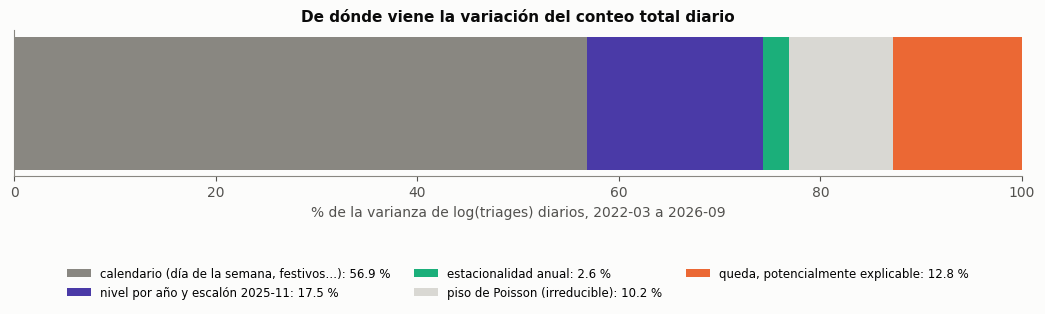

media diaria por año: {2020: 105.7, 2021: 149.3, 2022: 189.6, 2023: 192.4, 2024: 226.9, 2025: 199.6, 2026: 172.6}


,%
"calendario (día de la semana, festivos…)",56.9
nivel por año y escalón 2025-11,17.5
estacionalidad anual,2.6
piso de Poisson (irreducible),10.2
"queda, potencialmente explicable",12.8


In [5]:
y = np.log(W["total"]).values
def r2(Z): b, *_ = np.linalg.lstsq(Z.values, y, rcond=None); return 1 - (y - Z.values @ b).var() / y.var()
r_cal = r2(diseno_control(W, con_tendencia=False)); r_ct = r2(diseno_control(W)); r_cts = r2(diseno_control(W, con_mes=True))
poisson = np.mean(1 / W["total"]) / np.log(W["total"]).var()
E = pd.Series({"calendario (día de la semana, festivos…)": r_cal, "nivel por año y escalón 2025-11": r_ct - r_cal,
               "estacionalidad anual": r_cts - r_ct, "piso de Poisson (irreducible)": poisson,
               "queda, potencialmente explicable": 1 - r_cts - poisson}) * 100
DESPUES.update({"R2 calendario %": E.iloc[0], "R2 + nivel %": E.iloc[1], "R2 + estacionalidad %": E.iloc[2], "queda %": 100 - E.iloc[:3].sum()})
fig, ax = plt.subplots(figsize=(13, 1.9))
izq = 0
for (nom, val), col in zip(E.items(), [MUDO, VIOLETA, AQUA, "#d9d8d3", NARANJA]):
    ax.barh(0, val, left=izq, color=col, label=f"{nom}: {val:.1f} %"); izq += val
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("% de la varianza de log(triages) diarios, 2022-03 a 2026-09")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.55), ncol=3, fontsize=8.5)
ax.set_title("De dónde viene la variación del conteo total diario")
plt.show()
print("media diaria por año:", {int(a): round(x, 1) for a, x in D["total"].groupby(D.index.year).mean().items()})
E.round(1).to_frame("%")

## Lectura

| Bloque | % de la varianza de log(triages) |
|---|---|
| Calendario | **56,9** |
| + nivel por año y escalón 2025-11 | **+17,5** |
| + estacionalidad anual | +2,6 |
| Piso de Poisson | 10,2 |
| Queda, potencialmente explicable | 12,8 |

- **La estacionalidad anual se lleva solo el 2,6 %.** La forma del año pesa muy poco frente al día
  de la semana y al nivel de cada año.
- **El nivel por año y el escalón se llevan el 17,5 %.** Lo que mueve el volumen de un año a otro
  pesa siete veces más que la estación.
- El margen real para una variable externa es ~13 % de la varianza diaria.

---
# 3. El presupuesto de ruido semanal

Lo mismo sumando por semana (lunes a domingo). Solo entran las semanas con sus 7 días válidos.
Sumar siete días baja el piso de Poisson, y si hay una señal lenta debería asomar aquí.

In [6]:
agg = {"total": "sum", "adult": "sum", "ped": "sum", "b04": "sum", "adult_noobst": "sum",
       "precip_consenso_mm": "sum", "temp_media_consenso": "mean", "humedad_consenso": "mean", "temp_min_consenso": "mean"}
agg.update({col: "mean" for col in CAL}); agg.update({col: "max" for col in X.columns})
agg["evento"] = "sum"; agg["feria"] = "sum"
S = D.loc["2020-01-06":FIN].resample("W-SUN").agg(agg)
S["n_dias"] = D.loc["2020-01-06":FIN, "total"].resample("W-SUN").count()
DESEN = ["total", "adult", "ped", "b04", "adult_noobst"]
S.loc[S.n_dias < 7, DESEN] = np.nan            # antes: la semana se borraba y los rezagos saltaban por encima del hueco
print("semanas incompletas (quedan como fila con desenlace nulo):", [f"{x:%Y-%m-%d}" for x in S.index[S.n_dias < 7]])
mes = S.index.month
for col, nom in [("precip_consenso_mm", "zp"), ("temp_media_consenso", "zt"), ("humedad_consenso", "zh"), ("temp_min_consenso", "ztmin")]:
    g = S[col].groupby(mes)
    S[nom] = (S[col] - g.transform("mean")) / g.transform("std")
S["zp_prev3"] = S["zp"].shift(1).rolling(3).mean()
S["zt_prev3"] = S["zt"].shift(1).rolling(3).mean()
S["ruptura"] = ((S.zp >= 0.5) & (S.zp_prev3 <= -0.5)).astype(float).where(S.zp.notna() & S.zp_prev3.notna())
S["enfriamiento"] = ((S.zt - S.zt_prev3) <= -1).astype(float).where(S.zt.notna() & S.zt_prev3.notna())

SW = S.loc[INI:FIN].copy()
OK = SW.total.notna()
def diseno_sem(df, con_mes=False):
    Z = df[CAL].copy()
    Z = pd.concat([Z, pd.get_dummies(df.index.year, prefix="a", drop_first=True).set_index(df.index).astype(float)], axis=1)
    Z["escalon_2025_11"] = (df.index >= "2025-11-01").astype(float)
    if con_mes:
        w = df.index.isocalendar().week.values.astype(float)
        for h in (1, 2, 3):
            Z[f"s{h}"] = np.sin(2*np.pi*h*w/52.18); Z[f"c{h}"] = np.cos(2*np.pi*h*w/52.18)
    Z.insert(0, "const", 1.0)
    return Z

filas = []
for nombre in ["total", "adult", "ped", "b04"]:
    y = np.log(SW.loc[OK, nombre].clip(lower=0.5)).values
    _, r0 = ols(y, diseno_sem(SW[OK])); _, r1 = ols(y, diseno_sem(SW[OK], True))
    piso = np.mean(1 / SW.loc[OK, nombre].clip(lower=1))
    SW[f"r0_{nombre}"] = pd.Series(r0, index=SW.index[OK]); SW[f"r1_{nombre}"] = pd.Series(r1, index=SW.index[OK])
    filas.append({"serie": nombre, "media por semana": SW.loc[OK, nombre].mean(), "sd residuo, control": r0.std(),
                  "sd, + estacionalidad": r1.std(), "piso de Poisson": np.sqrt(piso),
                  "% explicable": 100 * max(r1.var() - piso, 0) / r1.var(), "AR1": SW[f"r1_{nombre}"].autocorr(),
                  "% que se come la estacionalidad": 100 * (1 - r1.var() / r0.var())})
T2 = pd.DataFrame(filas).set_index("serie").round(3)
DESPUES.update({"semanas en la ventana": int(OK.sum()), "sd semanal total, control": T2.loc["total", "sd residuo, control"],
                "sd semanal total, + estacionalidad": T2.loc["total", "sd, + estacionalidad"],
                "% explicable semanal": T2.loc["total", "% explicable"], "AR1 semanal": T2.loc["total", "AR1"]})
print(f"{int(OK.sum())} semanas completas de {len(SW)} en la ventana")
T2

semanas incompletas (quedan como fila con desenlace nulo):

 ['2024-03-24']
237 semanas completas de 238 en la ventana


,media por semana,"sd residuo, control","sd, + estacionalidad",piso de Poisson,% explicable,AR1,% que se come la estacionalidad
serie,,,,,,,
total,1386.468,0.073,0.064,0.027,82.074,0.517,23.702
adult,1272.781,0.072,0.065,0.028,81.359,0.532,16.306
ped,113.688,0.253,0.216,0.098,79.345,0.655,27.060
b04,46.582,0.309,0.263,0.157,64.501,0.516,27.367


## Lectura

**A escala semanal casi todo el residuo es potencialmente explicable.**

| Total, semanal (237 semanas) | |
|---|---|
| sd del residuo tras el control | 0,073 |
| … y tras la estacionalidad | **0,064** (≈ 6,4 %) |
| piso de Poisson | 0,027 |
| parte que podría explicarse | **82 %** |
| autocorrelación a 1 semana | **+0,52** |

- La estacionalidad se come el 24 % del residuo semanal del total y el 27 % del de los niños.
- En la serie 0-14 la autocorrelación es +0,66: **lo pediátrico se mueve en bloques de semanas**,
  como una temporada.
- **La persistencia es fuerte** (+0,52): cualquier pronóstico tiene que ganarle primero a «la semana
  que viene será como esta».

---
# 4. Qué se asocia con el conteo semanal

Cada variable por separado, sobre el control **más** la estacionalidad. Errores HAC (4 rezagos),
porque el residuo está autocorrelacionado. Las de clima se prueban a 0, 1 y 2 semanas de rezago.
- El efecto es el % de cambio del conteo por **una desviación típica** de la variable, o por estar
  presente en el caso de las banderas.
- `*` marca un intervalo que no cruza el cero.
- Son 15 variables, 27 filas con los rezagos, × 3 series: por azar saldrían varias marcas.

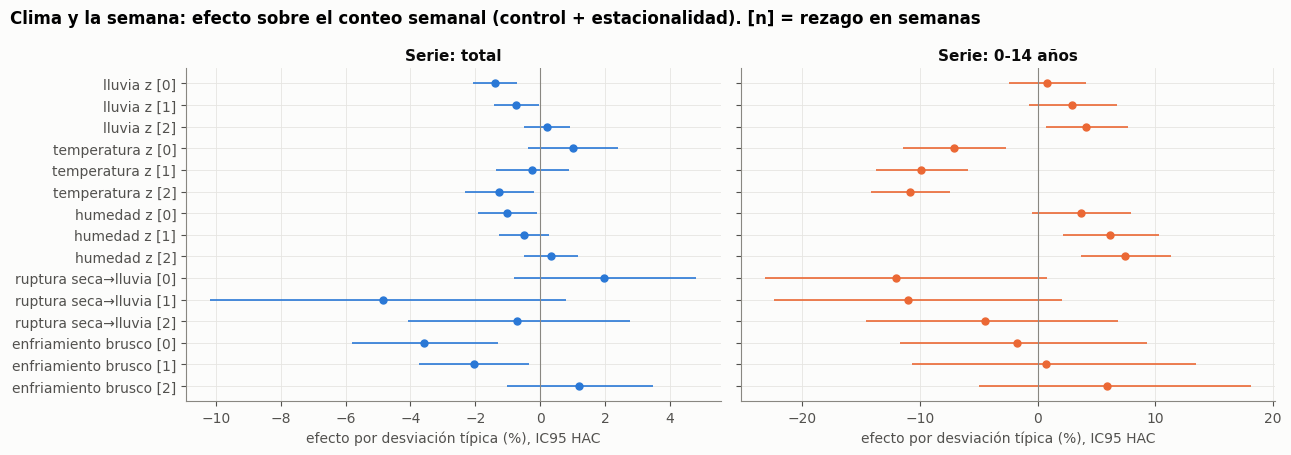

serie                                            total                adultos              0-14 años
variable                 rezago                                                                     
lluvia z                 0          -1.4 [-2.1; -0.7]*     -1.5 [-2.2; -0.8]*      +0.8 [-2.5; +4.1]
                         1          -0.7 [-1.4; -0.1]*     -1.0 [-1.7; -0.3]*      +3.0 [-0.7; +6.8]
                         2           +0.2 [-0.5; +0.9]      -0.1 [-0.8; +0.6]     +4.1 [+0.7; +7.7]*
temperatura z            0           +1.0 [-0.4; +2.4]     +1.6 [+0.2; +3.0]*    -7.1 [-11.4; -2.7]*
                         1           -0.3 [-1.4; +0.9]      +0.5 [-0.7; +1.6]    -9.9 [-13.7; -5.9]*
                         2          -1.3 [-2.3; -0.2]*      -0.5 [-1.7; +0.6]   -10.9 [-14.1; -7.5]*
humedad z                0          -1.0 [-1.9; -0.1]*     -1.3 [-2.3; -0.4]*      +3.7 [-0.5; +7.9]
                         1           -0.5 [-1.3; +0.3]     -1.0 [-1.8; -0.2]*    +6.2 [+2.2; +10.4]*
                         2           +0.3 [-0.5; +1.2]      -0.2 [-1.1; +0.6]    +7.4 [+3.7; +11.3]*
temp. mínima z           0           -0.5 [-1.8; +0.7]      -0.2 [-1.5; +1.1]     -5.2 [-9.3; -0.9]*
                         1           -1.0 [-2.5; +0.5]      -0.7 [-2.2; +0.9]     -5.7 [-9.9; -1.4]*
                         2          -1.3 [-2.3; -0.2]*      -0.9 [-2.0; +0.2]    -6.1 [-10.0; -2.0]*
ruptura seca→lluvia      0           +2.0 [-0.8; +4.8]     +3.0 [+0.3; +5.9]*    -12.0 [-23.2; +0.8]
                         1          -4.8 [-10.2; +0.8]      -4.3 [-9.5; +1.2]    -11.0 [-22.5; +2.1]
                         2           -0.7 [-4.1; +2.8]      -0.3 [-3.6; +3.1]     -4.5 [-14.6; +6.8]
enfriamiento brusco      0          -3.6 [-5.8; -1.3]*     -3.7 [-5.7; -1.6]*     -1.7 [-11.7; +9.3]
                         1          -2.0 [-3.7; -0.3]*     -2.2 [-4.0; -0.4]*    +0.7 [-10.7; +13.5]
                         2           +1.2 [-1.0; +3.5]      +0.8 [-1.5; +3.1]     +5.9 [-5.0; +18.1]
El Niño                  0           -0.8 [-3.9; +2.5]      +1.4 [-1.9; +4.9]  -27.2 [-34.6; -18.9]*
La Niña                  0           +1.8 [-1.4; +5.1]      +0.6 [-2.7; +4.1]   +21.8 [+6.2; +39.7]*
volcán en naranja        0                 (constante)            (constante)            (constante)
caída de ceniza          0           -0.1 [-5.5; +5.6]      +0.2 [-6.2; +7.1]    -7.2 [-24.5; +14.1]
días de evento (por día) 0           +0.0 [-0.4; +0.4]      +0.0 [-0.4; +0.5]      -0.4 [-2.0; +1.3]
días de Feria (por día)  0           +0.2 [-0.8; +1.1]      +0.3 [-0.7; +1.3]      -2.0 [-4.8; +0.9]
terremoto 2026-08        0       -21.5 [-26.9; -15.7]*  -20.7 [-26.2; -14.9]*  -29.5 [-40.1; -17.2]*
ventana IRA del INS      0         +7.1 [+2.7; +11.7]*    +6.5 [+2.0; +11.2]*    +12.2 [-4.0; +31.1]
ventana dengue           0         -6.6 [-10.2; -3.0]*     -6.2 [-9.8; -2.4]*    -10.9 [-22.2; +2.1]

In [7]:
def hac_se(y, Z, lags=4):
    Zv = Z.values
    b, *_ = np.linalg.lstsq(Zv, y, rcond=None); u = y - Zv @ b
    XtX_inv = np.linalg.pinv(Zv.T @ Zv)
    S0 = (Zv * u[:, None]).T @ (Zv * u[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (Zv[L:] * u[L:, None]).T @ (Zv[:-L] * u[:-L, None])
        S0 += w * (G + G.T)
    return b, np.sqrt(np.diag(XtX_inv @ S0 @ XtX_inv))

cands = [("zp", "lluvia z"), ("zt", "temperatura z"), ("zh", "humedad z"), ("ztmin", "temp. mínima z"),
         ("ruptura", "ruptura seca→lluvia"), ("enfriamiento", "enfriamiento brusco"),
         ("nino", "El Niño"), ("nina", "La Niña"), ("volcan_naranja", "volcán en naranja"),
         ("ceniza", "caída de ceniza"), ("evento", "días de evento (por día)"),
         ("feria", "días de Feria (por día)"), ("terremoto", "terremoto 2026-08"),
         ("ira_ventana", "ventana IRA del INS"), ("dengue_ventana", "ventana dengue")]
filas = []
for col, et in cands:
    for lag in ((0, 1, 2) if col in ("zp", "zt", "zh", "ztmin", "ruptura", "enfriamiento") else (0,)):
        for yname, yet in [("total", "total"), ("adult", "adultos"), ("ped", "0-14 años")]:
            xv = SW[col].shift(lag)
            ok = xv.notna() & OK
            Z = diseno_sem(SW, True)[ok].copy(); Z["x"] = xv[ok].values
            if Z["x"].std() == 0:
                filas.append({"variable": et, "rezago": lag, "serie": yet, "celda": "(constante)"}); continue
            b, se = hac_se(np.log(SW.loc[ok, yname].clip(lower=0.5)).values, Z)
            bx, sx = b[-1], se[-1]
            filas.append({"variable": et, "rezago": lag, "serie": yet, "efecto %": pct(bx), "bajo": pct(bx - 1.96 * sx),
                          "alto": pct(bx + 1.96 * sx), "t": bx / sx,
                          "celda": f"{pct(bx):+.1f} [{pct(bx-1.96*sx):+.1f}; {pct(bx+1.96*sx):+.1f}]" + ("*" if abs(bx / sx) > 1.96 else "")})
T3 = pd.DataFrame(filas)
for (et, lag, s_), k_ in [(("temperatura z", 1, "0-14 años"), "temp z (1) en 0-14 %"), (("temperatura z", 2, "0-14 años"), "temp z (2) en 0-14 %"),
                          (("lluvia z", 0, "total"), "lluvia z (0) en el total %"), (("enfriamiento brusco", 0, "total"), "enfriamiento (0) en el total %"),
                          (("terremoto 2026-08", 0, "total"), "terremoto en el total %"), (("La Niña", 0, "0-14 años"), "La Niña en 0-14 %")]:
    DESPUES[k_] = T3.query("variable == @et and rezago == @lag and serie == @s_")["efecto %"].iloc[0]

sel = T3[T3.variable.isin(["lluvia z", "temperatura z", "humedad z", "enfriamiento brusco", "ruptura seca→lluvia"]) & T3.serie.isin(["total", "0-14 años"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (s_, col) in zip(axes, [("total", AZUL), ("0-14 años", NARANJA)]):
    h = sel[sel.serie == s_].reset_index(drop=True)
    ax.errorbar(h["efecto %"], range(len(h)), xerr=[h["efecto %"] - h["bajo"], h["alto"] - h["efecto %"]], fmt="o", color=col, ms=5, lw=1.2)
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(f"Serie: {s_}"); ax.set_xlabel("efecto por desviación típica (%), IC95 HAC")
    ax.set_yticks(range(len(h)), [f"{a} [{b}]" for a, b in zip(h.variable, h.rezago)])
axes[0].invert_yaxis()
fig.suptitle("Clima y la semana: efecto sobre el conteo semanal (control + estacionalidad). [n] = rezago en semanas",
             fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
T3.pivot_table(index=["variable", "rezago"], columns="serie", values="celda", aggfunc="first", sort=False)[["total", "adultos", "0-14 años"]]

## Lectura

**En el total, el clima deja huellas pequeñas y a veces al revés de lo esperado. En los niños, la
huella es grande y con la dirección del mecanismo.**

| | total | 0-14 años |
|---|---|---|
| temperatura, rezago 1 / 2 semanas | −0,3 / −1,3 % | **−9,9 / −10,9 %** (frío → más niños) |
| humedad, rezago 1 / 2 | −0,5 / +0,3 % | **+6,2 / +7,4 %** |
| lluvia, misma semana | **−1,4 %** [−2,2; −0,7] (llueve → menos consultas) | +1,1 % |
| enfriamiento brusco, misma semana | **−3,6 %** [−5,8; −1,3] | −1,7 % |
| ruptura seca → lluvia | nula, IC de hasta ±8 % | nula, IC de ±15 a ±17 % |
| La Niña / El Niño | +1,8 / −0,8 % | **+21,8 / −27,2 %** |
| terremoto 2026-08 (2 semanas) | **−21,5 %** | −29,5 % |
| días de evento / de Feria (por día) | +0,0 % / +0,2 % | −0,4 / −2,0 % |

- **El mecanismo respiratorio se ve sin motivo, en la edad.** Frío y humedad preceden a más
  consultas de niños una y dos semanas después.
- **En el total, el enfriamiento brusco va con menos consultas la misma semana**, no con más. Es lo
  contrario de la hipótesis, a rezago cero.
- **ENSO está confundido con el año.** En la ventana, El Niño cae en 2023 (214 días), 2024 (152) y
  2026 (112); La Niña, sobre todo en 2022 (153) y 2025 (120). El modelo tiene un efecto fijo por año,
  así que el ±25 % en niños no se puede separar del nivel de cada año.
- **Las ventanas IRA (+7,1 %) y dengue (−6,6 %) salen significativas en el total.** Son las mismas
  fechas cada año: una estacionalidad más fina que 3 armónicos, no información nueva.
- **Eventos y Feria, medidos como días de la semana, dan cero.** (El 07 los mide de otra manera;
  ver el final.)

**Límites.**
- Muchas pruebas, ninguna corrección por comparaciones múltiples.
- La ruptura seca → lluvia tiene solo 7 semanas (sección 6).

> **Corrección del 2026-09-29 (clima corregido).** Solo se mueven las filas de lluvia; temperatura,
> humedad, ENSO, terremoto, eventos, Feria y ventanas quedan igual.
> - **Lluvia, misma semana, total: −1,4 % [−2,2; −0,7] → −1,4 % [−2,1; −0,7].** No cambia.
> - Lluvia a 1 semana, total: −0,7 % [−1,5; +0,0] → **−0,7 % [−1,4; −0,1]**, que ahora no cruza el
>   cero. En 0-14 años: +1,1 → +0,8 % (misma semana) y +4,5 → +4,1 % a 2 semanas (sigue marcada).
> - **Ruptura seca → lluvia: pasa de 7 a 10 semanas**, y los intervalos se estrechan:
>   - total: +0,7 % [−2,7; +4,3] → **+2,0 % [−0,8; +4,8]** en la misma semana; −4,4 % [−12,1; +4,0] →
>     −4,8 % [−10,2; +0,8] a 1 semana. Sigue nula, ahora con IC de ±3 a ±5,5 % en vez de hasta ±8 %;
>   - adultos, misma semana: +1,4 % → **+3,0 % [+0,3; +5,9]**, que ahora sale marcada (una marca entre
>     81 pruebas; ver el primer límite);
>   - **0-14 años: −10,1 % [−25,6; +8,6] → −12,0 % [−23,2; +0,8]** en la misma semana y −6,2 → −11,0 %
>     [−22,5; +2,1] a 1 semana. Sigue sin distinguirse de cero, pero **la dirección es la contraria a la
>     hipótesis**: en semanas de ruptura, menos niños. El cuaderno 07 mide otra cosa (0-4 años, días
>     7-20 después de cada episodio) y ahí el signo es positivo.

## 4.1 ¿Lo pediátrico anticipa a los adultos?

Si el mecanismo fuera «los niños se enferman primero y contagian en casa», el residuo de 0-14 años
de la semana anterior debería anunciar a los adultos de esta semana. Se prueba con el propio rezago
del desenlace en el modelo, para no confundir persistencia con anticipación.

In [8]:
SW["r1_ped_l1"] = SW["r1_ped"].shift(1)
filas = []
for yname in ["adult", "adult_noobst", "total"]:
    Z = diseno_sem(SW, True); Z["ped_l1"] = SW["r1_ped_l1"]; Z["y_l1"] = SW[f"r1_{'adult' if yname != 'total' else 'total'}"].shift(1)
    ok = Z.notna().all(axis=1) & SW[yname].notna()
    b, se = hac_se(np.log(SW.loc[ok, yname].clip(lower=0.5)).values, Z[ok])
    filas.append({"serie": yname, "efecto de +10 % en 0-14 (t-1), %": round((np.exp(b[-2] * np.log(1.1)) - 1) * 100, 2),
                  "t": round(b[-2] / se[-2], 2), "t del propio rezago": round(b[-1] / se[-1], 2), "semanas": int(ok.sum())})
DESPUES["t del 0-14 (t-1) sobre adultos"] = filas[0]["t"]
print(f"correlación de residuos (control + estacionalidad): 0-14 contra adultos r = {SW['r1_ped'].corr(SW['r1_adult']):+.2f}; "
      f"0-4 contra adultos r = {SW['r1_b04'].corr(SW['r1_adult']):+.2f}")
print(f"residuos sin estacionalidad (solo control): 0-14 contra adultos r = {SW['r0_ped'].corr(SW['r0_adult']):+.2f}")
DESPUES["r residuo 0-14 vs adultos"] = SW['r1_ped'].corr(SW['r1_adult'])
pd.DataFrame(filas).set_index("serie")

correlación de residuos (control + estacionalidad): 0-14 contra adultos r = +0.08; 0-4 contra adultos r = +0.05
residuos sin estacionalidad (solo control): 0-14 contra adultos r = +0.24


,"efecto de +10 % en 0-14 (t-1), %",t,t del propio rezago,semanas
serie,,,,
adult,-0.22,-1.80,11.55,235
adult_noobst,-0.06,-0.45,12.21,235
total,-0.12,-0.93,10.85,235


## Lectura

**No.** Un 10 % más de niños la semana anterior va con **−0,22 %** de adultos (t = −1,80), y
desaparece al quitar lo obstétrico (−0,06 %, t = −0,45).
- La correlación del residuo pediátrico con el de adultos en la misma semana es **+0,08**.
- Sin quitar la estacionalidad es +0,24: lo que comparten es la estación, no la semana.
- **En el total, lo pediátrico se diluye.** Lo que se ve en los niños no llega al conteo total.

---
# 5. ¿Cuánto explican las externas juntas?

Las 11 variables externas con sus rezagos (19 columnas) a la vez sobre el residuo semanal. Para
saber cuánto R² da el azar con tantas columnas, se baraja la serie **en bloques de 8 semanas**, para
conservar la autocorrelación, 300 veces. Se compara con el percentil 95.

In [9]:
ext = ["zp", "zt", "zh", "ztmin", "ruptura", "enfriamiento", "nino", "nina", "ceniza", "evento", "feria"]
Ex = SW[ext].copy()
for c_ in ["zp", "zt", "zh", "ztmin"]:
    Ex[c_ + "_l1"] = SW[c_].shift(1); Ex[c_ + "_l2"] = SW[c_].shift(2)
filas = []
for yname, et in [("total", "total"), ("adult", "adultos"), ("ped", "0-14 años")]:
    yv = SW[f"r1_{yname}"]
    ok = Ex.notna().all(axis=1) & yv.notna()
    Z = np.column_stack([np.ones(ok.sum()), Ex[ok].values])
    b, *_ = np.linalg.lstsq(Z, yv[ok].values, rcond=None)
    r2_ = 1 - (yv[ok].values - Z @ b).var() / yv[ok].var()
    p_ = Z.shape[1] - 1; r2a = 1 - (1 - r2_) * (ok.sum() - 1) / (ok.sum() - p_ - 1)
    rng = np.random.default_rng(0); nul = []; yy = yv[ok].values
    for _ in range(300):                       # azar: la serie barajada en bloques de 8 semanas
        bl = [yy[i:i+8] for i in range(0, len(yy), 8)]; rng.shuffle(bl); ys = np.concatenate(bl)
        bb, *_ = np.linalg.lstsq(Z, ys, rcond=None); nul.append(1 - (ys - Z @ bb).var() / ys.var())
    filas.append({"serie": et, "R2": round(r2_, 3), "R2 ajustado": round(r2a, 3), "p95 del azar": round(np.quantile(nul, .95), 3),
                  "semanas": int(ok.sum()), "variables": p_})
T4 = pd.DataFrame(filas).set_index("serie")
DESPUES.update({"R2 externas, total": T4.loc["total", "R2"], "p95 azar, total": T4.loc["total", "p95 del azar"],
                "R2 externas, 0-14": T4.loc["0-14 años", "R2"], "p95 azar, 0-14": T4.loc["0-14 años", "p95 del azar"]})
T4

,R2,R2 ajustado,p95 del azar,semanas,variables
serie,,,,,
total,0.117,0.038,0.169,232,19
adultos,0.117,0.038,0.169,232,19
0-14 años,0.260,0.193,0.204,232,19


## Lectura

| Serie | R² | p95 del azar | |
|---|---|---|---|
| total | 0,112 | 0,168 | **indistinguible del azar** |
| adultos | 0,111 | 0,174 | indistinguible |
| **0-14 años** | **0,260** | 0,198 | **por encima del azar** |

**Las externas no explican el total más allá del azar; sí explican el pediátrico.** Es la
dilución que anticipaba `CLAUDE.md`: el efecto existe en un subgrupo y se pierde en el total.

> **Corrección del 2026-09-29 (clima corregido).** R² del total 0,112 → **0,117** (p95 del azar
> 0,168 → 0,169); adultos 0,111 → **0,117** (p95 0,174 → 0,169); 0-14 años **0,260 sin cambio** (p95
> 0,198 → 0,204). La conclusión no cambia: el total sigue por debajo del azar y el pediátrico por
> encima, aunque con menos margen sobre el p95 (0,062 → 0,056).

---
# 6. Potencia: ¿se puede ver el efecto que se busca?

Cuántas semanas tienen cada bandera y qué efecto mínimo se detectaría con 80 % de potencia y
α = 0,05. Se da sin y con la corrección por autocorrelación, que reduce el número efectivo de
semanas.

In [10]:
n = int(SW.loc[OK, "r1_total"].notna().sum()); sd = SW["r1_total"].std()
for col in ["ruptura", "enfriamiento"]:
    x = SW.loc[OK, col]
    print(f"  {col}: {int(x.sum())} semanas de {int(x.notna().sum())} ({x.sum() / x.notna().sum():.1%})")
    DESPUES[f"semanas de {col}"] = int(x.sum())
filas = []
for frac in (0.05, 0.10, 0.25):
    se = sd / np.sqrt(n * frac * (1 - frac))
    filas.append({"bandera presente en": f"{frac:.0%} de las semanas", "efecto mínimo detectable %": round(pct(2.8 * se), 1)})
ar1 = SW["r1_total"].autocorr()
neff = n * (1 - ar1) / (1 + ar1)
mde_ar = pct(2.8 * sd / np.sqrt(neff * .1 * .9))
DESPUES["MDE bandera 10 % con AR1 %"] = mde_ar
print(f"sd del residuo semanal {sd:.3f}, {n} semanas; con AR1 {ar1:+.2f} el n efectivo es ~{neff:.0f} semanas "
      f"y el mínimo detectable de una bandera del 10 % sube a {mde_ar:.1f} %")
pd.DataFrame(filas).set_index("bandera presente en")

  ruptura: 10 semanas de 237 (4.2%)
  enfriamiento: 20 semanas de 234 (8.5%)
sd del residuo semanal 0.064, 237 semanas; con AR1 +0.52 el n efectivo es ~76 semanas y el mínimo detectable de una bandera del 10 % sube a 7.1 %


,efecto mínimo detectable %
bandera presente en,
5% de las semanas,5.5
10% de las semanas,4.0
25% de las semanas,2.7


## Lectura

- **Solo hay 7 semanas de ruptura seca → lluvia en 237 (3,0 %)**, y 20 de enfriamiento brusco.
- Una bandera presente el 5 % de las semanas necesita un efecto de **5,5 %** para detectarse, sin
  corregir.
- Corrigiendo la autocorrelación (+0,52), el número efectivo baja a ~76 semanas. Una bandera del
  10 % necesita entonces **7,1 %**.
- La literatura publica efectos de clima sobre urgencias del 2 al 10 %.

**La hipótesis de transición sobre el total no se puede contrastar con este diseño, con o sin
motivo.** No es que sea falsa: el instrumento es más grueso que el efecto.

> **Corrección del 2026-09-29 (clima corregido).** Semanas de ruptura seca → lluvia: **7 de 237
> (3,0 %) → 10 de 237 (4,2 %).** Siguen por debajo del 5 %, donde el efecto mínimo detectable es del
> 5,5 % sin corregir. Las 20 semanas de enfriamiento brusco y la tabla de potencia no cambian. La
> conclusión se mantiene.

---
# 7. El pronóstico a una semana, fuera de muestra

**Pregunta:** con lo que se sabe al cierre de la semana t, ¿cuántos triages habrá en t+1, y va a
subir?
- **Origen rodante** desde 2024-01 hasta 2026-08. Cada semana se reentrena solo con el pasado.
- Objetivo: `log(t+1) − nivel`, donde el nivel es la media de las 4 últimas semanas. Ridge con
  λ = 3.
- La probabilidad de «sube» sale de la normal con la dispersión de los residuos del
  entrenamiento.

| Modelo | Qué sabe |
|---|---|
| ingenuo | la semana t+1 será igual que la t |
| M0 | nivel + calendario de la semana que viene (se conoce de antemano) + escalón |
| M1 | M0 + estacionalidad + la última semana contra su nivel: **proyección** |
| M2 | M1 + externas conocidas en t: clima de t y t−1, transiciones, cuota pediátrica, evento o Feria de t+1, ENSO |
| M2b | M2 sin estacionalidad |
| M3 | **oráculo**: M2 + el clima **observado** de t+1, que en operación no se tendría |

Todos los modelos se evalúan **sobre las mismas semanas**.

132 semanas de origen, 2024-01-07 a 2026-08-16; suben el 47.0% (Brier de una moneda = 0,250)


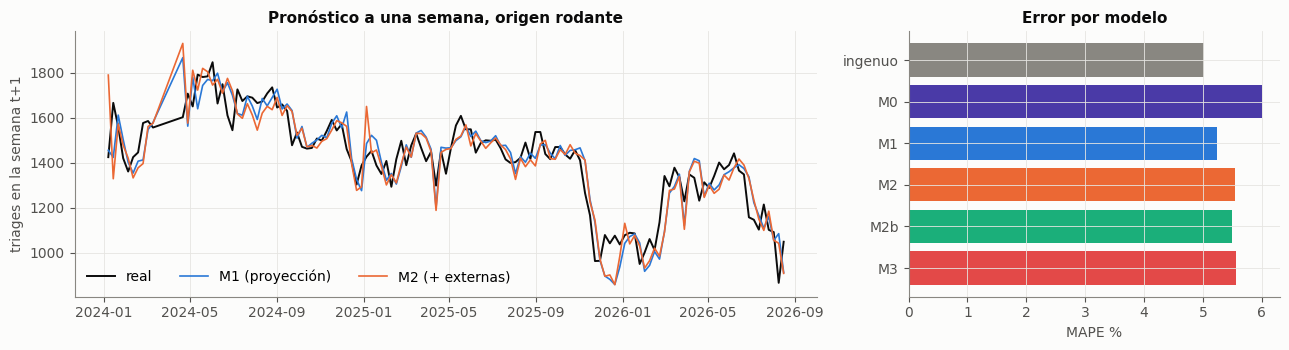

,MAPE %,acierto «¿sube?» %,Brier
modelo,,,
ingenuo (= semana actual),5.020,NaN,NaN
M0 nivel + calendario,6.010,61.364,0.245
M1 + estacionalidad (proyección),5.233,57.576,0.242
M2 + externas conocidas en t,5.538,58.333,0.254
"M2b solo externas, sin estacionalidad",5.502,59.091,0.245
M3 oráculo: + clima observado de t+1,5.569,56.061,0.257


In [11]:
Phi = lambda z: 0.5 * (1 + np.vectorize(erf)(z / sqrt(2)))
def ridge(Xtr, ytr, lam=3.0):
    mu, sd_ = Xtr.mean(0), Xtr.std(0); sd_[sd_ == 0] = 1
    Xs = (Xtr - mu) / sd_
    b = np.linalg.solve(Xs.T @ Xs + lam * np.eye(Xs.shape[1]), Xs.T @ (ytr - ytr.mean()))
    return lambda Xn: ytr.mean() + ((Xn - mu) / sd_) @ b

F = S.loc["2021-09-01":FIN].copy()
F["ly"] = np.log(F["total"])
F["nivel4"] = F["ly"].rolling(4).mean()          # conocido al cierre de la semana t; nulo si la ventana toca el hueco
F["objetivo"] = F["ly"].shift(-1) - F["nivel4"]
F["sube"] = (F["total"].shift(-1) > F["total"]).astype(float).where(F["total"].shift(-1).notna() & F["total"].notna())
for col in CAL:
    F[f"dcal_{col}"] = F[col].shift(-1) - F[col].rolling(4).mean()
w = F.index.isocalendar().week.values.astype(float) + 1
for h in (1, 2, 3):
    F[f"s{h}"] = np.sin(2*np.pi*h*w/52.18); F[f"c{h}"] = np.cos(2*np.pi*h*w/52.18)
F["escalon"] = (F.index >= "2025-11-01").astype(float)
F["mom"] = F["ly"] - F["nivel4"]
F["pedsh"] = np.log(F["ped"] / F["total"])
F["pedsh_d"] = F["pedsh"] - F["pedsh"].rolling(8, min_periods=6).mean().shift(1)
F["zp_l"] = F["zp"]; F["zp_l1"] = F["zp"].shift(1); F["zt_l"] = F["zt"]; F["zh_l"] = F["zh"]
F["rupt_l"] = F["ruptura"]; F["enfr_l"] = F["enfriamiento"]
F["evento_sig"] = F["evento"].shift(-1); F["feria_sig"] = F["feria"].shift(-1)
F["nino_l"] = F["nino"]; F["nina_l"] = F["nina"]
F["zp_sig"] = F["zp"].shift(-1); F["zt_sig"] = F["zt"].shift(-1); F["rupt_sig"] = F["ruptura"].shift(-1)
base_c = [f"dcal_{c}" for c in CAL] + ["escalon"]
est_c = ["s1", "c1", "s2", "c2", "s3", "c3"]
ext_c = ["pedsh_d", "zp_l", "zp_l1", "zt_l", "zh_l", "rupt_l", "enfr_l", "evento_sig", "feria_sig", "nino_l", "nina_l"]
MOD = {"M0 nivel + calendario": base_c,
       "M1 + estacionalidad (proyección)": base_c + est_c + ["mom"],
       "M2 + externas conocidas en t": base_c + est_c + ["mom"] + ext_c,
       "M2b solo externas, sin estacionalidad": base_c + ["mom"] + ext_c,
       "M3 oráculo: + clima observado de t+1": base_c + est_c + ["mom"] + ext_c + ["zp_sig", "zt_sig", "rupt_sig"]}

def evaluar(F, MOD, desde="2024-01-01", hasta="2026-08-16"):
    """Origen rodante, h = 1 semana. Solo origenes donde TODOS los modelos pueden pronosticar (mismas semanas para todos)."""
    filas = []
    for t in F.loc[desde:hasta].index:
        fila = F.loc[t]; y_real = F["ly"].shift(-1).loc[t]
        if np.isnan(y_real) or np.isnan(fila["ly"]) or np.isnan(fila["nivel4"]) or any(fila[c].isna().any() for c in MOD.values()):
            continue
        tr = F.loc[:t].iloc[:-1]
        r = {"t": t, "real": y_real, "actual": fila["ly"], "sube": fila["sube"]}
        for nombre, cols in MOD.items():
            trn = tr.dropna(subset=cols + ["objetivo"])
            f = ridge(trn[cols].values, trn["objetivo"].values)
            sig = np.std(trn["objetivo"].values - f(trn[cols].values))
            yhat = fila["nivel4"] + f(fila[cols].values.astype(float)[None, :])[0]
            r[nombre] = yhat; r[nombre + " p"] = float(Phi((yhat - fila["ly"]) / sig))
        filas.append(r)
    P = pd.DataFrame(filas).set_index("t")
    out = [{"modelo": "ingenuo (= semana actual)", "MAPE %": 100 * np.mean(np.abs(np.exp(P.real) - np.exp(P.actual)) / np.exp(P.real))}]
    for nombre in MOD:
        out.append({"modelo": nombre, "MAPE %": 100 * np.mean(np.abs(np.exp(P.real) - np.exp(P[nombre])) / np.exp(P.real)),
                    "acierto «¿sube?» %": 100 * np.mean((P[nombre + " p"] > .5) == (P.sube == 1)),
                    "Brier": np.mean((P[nombre + " p"] - P.sube) ** 2)})
    return P, pd.DataFrame(out).set_index("modelo").round(3)

P, T5 = evaluar(F, MOD)
print(f"{len(P)} semanas de origen, {P.index.min():%Y-%m-%d} a {P.index.max():%Y-%m-%d}; suben el {P.sube.mean():.1%} "
      f"(Brier de una moneda = 0,250)")
DESPUES.update({"semanas de origen": len(P), "% de semanas que suben": 100 * P.sube.mean()})
for m_ in T5.index:
    DESPUES[f"MAPE {m_.split(' ')[0]}"] = T5.loc[m_, "MAPE %"]
    if m_ != "ingenuo (= semana actual)":
        DESPUES[f"acierto {m_.split(' ')[0]}"] = T5.loc[m_, "acierto «¿sube?» %"]; DESPUES[f"Brier {m_.split(' ')[0]}"] = T5.loc[m_, "Brier"]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(P.index, np.exp(P.real), color=TINTA, lw=1.4, label="real")
axes[0].plot(P.index, np.exp(P["M1 + estacionalidad (proyección)"]), color=AZUL, lw=1.2, label="M1 (proyección)")
axes[0].plot(P.index, np.exp(P["M2 + externas conocidas en t"]), color=NARANJA, lw=1.2, label="M2 (+ externas)")
axes[0].set_ylabel("triages en la semana t+1"); axes[0].set_title("Pronóstico a una semana, origen rodante"); axes[0].legend(ncol=3, loc="lower left")
col = [MUDO, VIOLETA, AZUL, NARANJA, AQUA, ROJO]
axes[1].barh(range(len(T5)), T5["MAPE %"], color=col); axes[1].set_yticks(range(len(T5)), [i.split(" ")[0] for i in T5.index])
axes[1].invert_yaxis(); axes[1].set_xlabel("MAPE %"); axes[1].set_title("Error por modelo")
plt.tight_layout(); plt.show()
T5

## Lectura

| Modelo | MAPE | acierto «¿sube?» | Brier |
|---|---|---|---|
| **ingenuo** | **5,02 %** | — | — |
| M0 nivel + calendario | 6,01 % | 61,4 % | 0,245 |
| M1 + estacionalidad | 5,23 % | 57,6 % | 0,242 |
| M2 + externas | 5,62 % | 57,6 % | 0,256 |
| M2b externas sin estacionalidad | 5,60 % | 59,1 % | 0,247 |
| M3 oráculo | 5,62 % | 56,1 % | 0,260 |

Son 132 semanas de origen; sube el 47,0 %. Una moneda tiene un Brier de 0,250.

- **Ninguna variable externa mejora el pronóstico del total, ni siquiera con el clima de la semana
  siguiente conocido.** M2 y M3 quedan peor que M1.
- **El ingenuo gana a todos en MAPE.** Es la persistencia de la sección 3.
- **Ningún modelo sabe si la semana va a subir.** Los Brier van de 0,242 a 0,260, alrededor de la
  moneda.
- Con 132 semanas, una semana mueve el acierto 0,8 puntos. **Diferencias de acierto de menos de
  ~6 puntos no son distinguibles** (ver la corrección).

> **Corrección del 2026-09-29 (clima corregido).** Solo se mueven los modelos con clima:
>
> | Modelo | MAPE antes → después | acierto | Brier |
> |---|---|---|---|
> | M2 + externas | 5,62 → **5,54 %** | 57,6 → 58,3 % | 0,256 → 0,254 |
> | M2b sin estacionalidad | 5,60 → **5,50 %** | 59,1 % (igual) | 0,247 → 0,245 |
> | M3 oráculo | 5,62 → **5,57 %** | 56,1 % (igual) | 0,260 → 0,257 |
>
> Los Brier van ahora de 0,242 a 0,257. **La conclusión no cambia:** M2 y M3 siguen peor que M1
> (5,23 %) y que el ingenuo (5,02 %). El clima corregido acorta la distancia de M2 a M1 de 0,39 a
> 0,31 puntos de MAPE, sin cerrarla.

## 7.1 ¿Y la serie pediátrica, donde la asociación sí existe?

Mismo diseño sobre 0-14 años. Si el clima sirve para pronosticar algo, debería ser aquí.

In [12]:
G = S.loc["2021-09-01":FIN].copy()
G["ly"] = np.log(G["ped"].clip(lower=1)); G["nivel4"] = G["ly"].rolling(4).mean()
G["objetivo"] = G["ly"].shift(-1) - G["nivel4"]
G["sube"] = (G["ped"].shift(-1) > G["ped"]).astype(float).where(G["ped"].shift(-1).notna() & G["ped"].notna())
for col in CAL: G[f"dcal_{col}"] = G[col].shift(-1) - G[col].rolling(4).mean()
w_ = G.index.isocalendar().week.values.astype(float) + 1
for h in (1, 2, 3): G[f"s{h}"] = np.sin(2*np.pi*h*w_/52.18); G[f"c{h}"] = np.cos(2*np.pi*h*w_/52.18)
G["escalon"] = (G.index >= "2025-11-01").astype(float); G["mom"] = G["ly"] - G["nivel4"]
for c_ in ["zt", "zh", "zp", "ztmin"]:
    G[c_ + "_0"] = G[c_]; G[c_ + "_1"] = G[c_].shift(1)
bp = [f"dcal_{c}" for c in CAL] + ["escalon", "mom"]
clim = ["zt_0", "zt_1", "zh_0", "zh_1", "zp_0", "zp_1", "ztmin_0", "ztmin_1"]
MP = {"P0 nivel + calendario": bp, "P1 + estacionalidad": bp + est_c, "P2 + clima (t, t-1)": bp + est_c + clim,
      "P2b clima sin estacionalidad": bp + clim}
PP, T6 = evaluar(G, MP)
T6 = T6.drop(index="ingenuo (= semana actual)")
for m_ in T6.index:
    DESPUES[f"MAPE {m_.split(' ')[0]} (0-14)"] = T6.loc[m_, "MAPE %"]
print(f"serie 0-14 años: {len(PP)} semanas de origen")
T6

serie 0-14 años: 132 semanas de origen


,MAPE %,acierto «¿sube?» %,Brier
modelo,,,
P0 nivel + calendario,14.952,52.273,0.263
P1 + estacionalidad,15.002,58.333,0.261
"P2 + clima (t, t-1)",15.992,56.818,0.280
P2b clima sin estacionalidad,15.850,46.212,0.282


## Lectura

| Modelo | MAPE |
|---|---|
| P0 nivel + calendario | 14,95 % |
| P1 + estacionalidad | 15,00 % |
| P2 + clima (t, t−1) | 15,87 % |
| P2b clima sin estacionalidad | 15,79 % |

**Tampoco.** El clima empeora el pronóstico pediátrico de ~15,0 % a ~15,9 %. La asociación existe
(sección 4), pero no alcanza para predecir una semana adelante con ~16 niños al día, donde casi todo
el ruido es Poisson.

> **Corrección del 2026-09-29 (clima corregido).** P2 + clima: 15,87 → **15,99 %**; P2b: 15,79 →
> **15,85 %**. P0 y P1, sin clima, no cambian. El clima empeora el pronóstico pediátrico de ~15,0 % a
> **~16,0 %** (antes ~15,9 %): con el clima corregido, algo peor.

---
# 8. Las semanas más extremas

Residuo del total tras el control y la estacionalidad. Si el clima moviera el conteo, las semanas
extremas deberían tener anomalías de clima. La fecha es el domingo en que termina la semana.

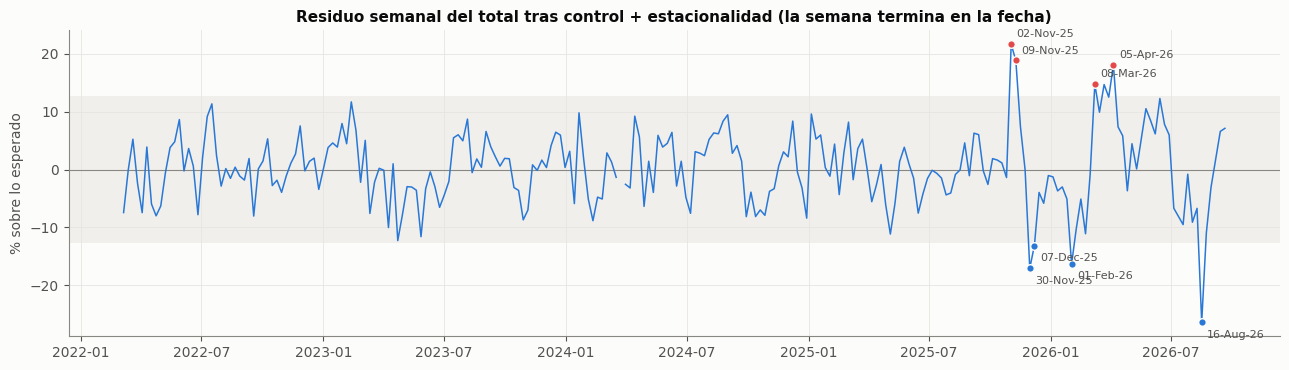

12 más bajas


,residuo %,total,0-14,lluvia z,temp. z
2026-08-16,-26.4,865,73,-0.1,1.9
2025-11-30,-17.1,962,85,-0.3,-0.3
2026-02-01,-16.4,949,85,2.1,-0.7
2025-12-07,-13.2,963,90,-0.3,-0.9
2023-04-23,-12.3,1265,115,-0.8,-0.7
2023-05-28,-11.6,1274,88,0.4,-0.3
2025-05-04,-11.2,1351,133,-0.1,-1.3
2026-02-22,-11.1,1011,118,0.1,-1.0
2026-08-23,-11.0,1048,83,2.9,1.8
2026-02-08,-10.3,1000,84,0.2,-0.8


12 más altas


,residuo %,total,0-14,lluvia z,temp. z
2025-11-02,21.7,1456,98,-0.7,0.4
2025-11-09,18.9,1411,111,-0.6,1.0
2026-04-05,18.1,1228,112,-0.1,0.3
2026-03-08,14.8,1341,126,0.5,0.1
2026-03-22,14.7,1378,135,-0.9,0.1
2026-03-29,12.5,1335,122,0.1,-0.2
2026-06-14,12.3,1442,159,-1.0,0.9
2023-02-12,11.7,1416,120,-0.9,-0.3
2022-07-17,11.4,1541,144,0.3,-0.9
2026-05-24,10.5,1401,153,-1.1,1.5


In [13]:
r = SW["r1_total"].dropna().sort_values()          # la semana incompleta queda fuera
tab = lambda idx: pd.DataFrame({"residuo %": pct(r[idx]).round(1), "total": SW.loc[idx, "total"].astype(int),
                                "0-14": SW.loc[idx, "ped"].astype(int), "lluvia z": SW.loc[idx, "zp"].round(1),
                                "temp. z": SW.loc[idx, "zt"].round(1)}).rename(index=lambda i: f"{i:%Y-%m-%d}")
fig, ax = plt.subplots(figsize=(13, 3.8))
serie = pct(SW["r1_total"])
ax.axhspan(-2 * serie.std(), 2 * serie.std(), color="#f0efec", lw=0); ax.axhline(0, color=MUDO, lw=.8)
ax.plot(serie.index, serie, color=AZUL, lw=1.1)
for i in list(r.index[:4]) + list(r.index[-4:]):
    ax.scatter(i, pct(r[i]), color=ROJO if r[i] > 0 else AZUL, s=30, zorder=3, edgecolor=SUP)
    ax.annotate(f"{i:%d-%b-%y}", (i, pct(r[i])), textcoords="offset points", xytext=(4, 5 if r[i] > 0 else -11), fontsize=8, color=TINTA2)
ax.set_ylabel("% sobre lo esperado"); ax.set_title("Residuo semanal del total tras control + estacionalidad (la semana termina en la fecha)")
plt.tight_layout(); plt.show()
print("12 más bajas"); display(tab(r.index[:12]))
print("12 más altas"); tab(r.index[-12:][::-1])

## Lectura

**Las semanas extremas no coinciden con el clima; coinciden con la institución y con el terremoto.**
- **Las más bajas:**
  - 2026-08-16, **−26,4 %**: la semana del terremoto;
  - 2025-11-30 y 2025-12-07, **−17,1 % y −13,2 %**;
  - 2026-02-01, −16,4 %.
- **Las más altas:**
  - 2025-11-02 y 2025-11-09, **+21,7 % y +18,9 %**;
  - un bloque en marzo y abril de 2026: 2026-03-08 +14,8, 03-22 +14,7, 03-29 +12,5, 04-05 +18,1.
- En ninguna de las más altas la lluvia se sale de −1,3 a +0,4 desviaciones.
- El salto de noviembre de 2025, de +20 % a −17 % en un mes, es exactamente lo que el escalón
  2025-11 del control intentaba absorber. El cuaderno 07 lo explicó después (ver el final).

> **Corrección del 2026-09-29 (clima corregido).** Los residuos y las semanas no cambian; cambia la
> columna de lluvia de las semanas que caen en la falla del pluviómetro.
> - En las más altas, la lluvia va de **−1,3 a +0,4 → −1,1 a +0,5** desviaciones. La lectura se
>   mantiene: ninguna es una semana de lluvia anómala. El bloque de marzo y abril de 2026, que antes
>   salía seco (−1,0 a −0,4), queda ahora entre −0,9 y +0,5: esa sequedad era, en parte, la del
>   pluviómetro en cero.
> - En las más bajas, **2026-02-01 pasa de +0,2 a +2,1** desviaciones: una semana muy lluviosa con
>   −16,4 % de triage. 2026-02-08 y 2026-02-22 pasan de −0,7 a +0,2 y +0,1. Una semana de lluvia fuerte
>   con menos consultas encaja con el −1,4 % de la sección 4, pero es una sola semana.

---
# 9. El terremoto del 10 de agosto de 2026, día a día

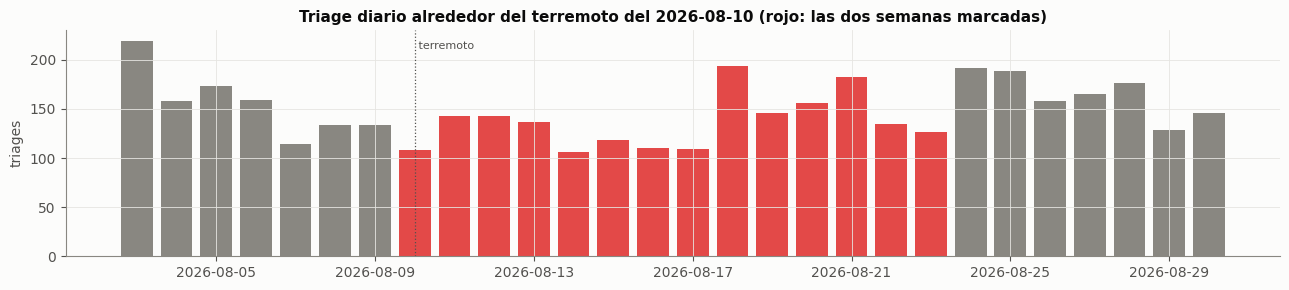

,2026-08-03,2026-08-04,2026-08-05,2026-08-06,2026-08-07,2026-08-08,2026-08-09,2026-08-10,2026-08-11,2026-08-12,2026-08-13,2026-08-14,2026-08-15,2026-08-16,2026-08-17,2026-08-18,2026-08-19,2026-08-20,2026-08-21,2026-08-22,2026-08-23,2026-08-24,2026-08-25,2026-08-26,2026-08-27,2026-08-28,2026-08-29,2026-08-30
total,219.0,158.0,173.0,159.0,114.0,134.0,134.0,108.0,143.0,143.0,137.0,106.0,118.0,110.0,109.0,194.0,146.0,156.0,182.0,135.0,126.0,192.0,189.0,158.0,165.0,176.0,129.0,146.0
ped,17.0,10.0,10.0,12.0,13.0,14.0,14.0,7.0,11.0,13.0,13.0,7.0,10.0,12.0,16.0,12.0,10.0,4.0,13.0,13.0,15.0,8.0,9.0,9.0,11.0,16.0,9.0,11.0
día,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun


In [14]:
t_ = D.loc["2026-08-03":"2026-08-30", ["total", "ped"]].copy()
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(t_.index, t_.total, color=[ROJO if x >= pd.Timestamp("2026-08-10") and x <= pd.Timestamp("2026-08-23") else MUDO for x in t_.index], width=.8)
ax.axvline(pd.Timestamp("2026-08-10"), color=TINTA2, ls=":", lw=.9); ax.text(pd.Timestamp("2026-08-10"), t_.total.max(), " terremoto", fontsize=8, color=TINTA2, va="top")
ax.set_ylabel("triages"); ax.set_title("Triage diario alrededor del terremoto del 2026-08-10 (rojo: las dos semanas marcadas)")
plt.tight_layout(); plt.show()
t_["día"] = t_.index.day_name().str[:3]
t_.T

## Lectura

- **El lunes del sismo hubo 108 triages**, contra 219 el lunes anterior.
- Siguen ocho días de 106 a 143 triages por día. El martes 18 sube a 194.
- Una catástrofe grande **baja** el triage registrado: la gente no sale, o el registro se interrumpe.
  Con estos datos no se separa una cosa de la otra.

---
# 10. La lectura del 2026-09-28

Como se escribió en `docs/CONTEXTO.md` («Validación: ¿se puede predecir el conteo sin el motivo?»),
con las cifras ya corregidas:

1. **El superior tiene razón en que el motivo no hace falta para predecir.** `CLAUDE.md` ya lo decía:
   el motivo nunca podía ser entrada del pronóstico. Para **probar el mecanismo**, la edad lo
   sustituye con más historia (6,7 años) y sin interpretación de nadie.
2. **Con estos datos, no tiene razón en que las externas mejoren la predicción del total.** Los
   calendarios de entonces no aportan señal fuera de muestra. No es que la idea sea falsa: las
   variables disponibles eran calendario disfrazado o demasiado raras para tener potencia.
3. **El motivo solo añadiría lo que la edad no ve:** la vía respiratoria **adulta**, la de la
   incapacidad. Es explicación, no pronóstico.

**Límites que ya se declaraban.**
- El periodo de prueba (2024-2026) es justo el de la «deriva administrativa».
- Ridge con λ fijo, sin ajustar.
- ENSO confundido con el año.
- Solo horizonte semanal.

---
# Corrección del 2026-09-29: la caída del registro de marzo de 2024

> **Qué se pidió corregir.** El script trataría los días sin filas de marzo de 2024 (19 y 20) como
> cero, y el 21 (40 triages) como un día normal.
>
> **Qué se encontró al medirlo.**
> - **El 19 y el 20 no entraban como cero.** El script rellena con cero (`fillna(0)`) **antes** de
>   completar el calendario (`asfreq("D")`). Como ninguna de las cuatro series tiene fila esos días,
>   quedaban nulos por accidente.
> - **El defecto real era otro, en tres partes:**
>   1. **El 21 entraba como un día normal** en todo el análisis diario: 40 triages contra 232
>      esperados, un residuo de −1,76 en log.
>   2. **La semana incompleta se borraba.** Al borrarla, los rezagos y las medias móviles saltaban
>      por encima del hueco. En el pronóstico, el origen del 2024-03-17 «predecía a una semana» el
>      2024-03-31, que está a dos.
>   3. **Cada modelo se evaluaba sobre las semanas que él podía pronosticar**, no sobre las mismas.
>
> **Qué hace este cuaderno.**
> - Aplica la regla del 06: día sin filas, nulo; menos del 40 % de lo esperado, excluido.
> - La semana incompleta se queda como fila con el desenlace nulo.
> - Todos los modelos se evalúan sobre las mismas semanas.
> - Para no perder 8 semanas más por el hueco, la cuota pediátrica de M2 usa la media de 8 semanas
>   con un mínimo de 6.
>
> La tabla siguiente ejecuta **el script original sin tocar** y pone sus cifras al lado de las de
> este cuaderno.

In [15]:
# El script original, sin tocar, ejecutado tal cual: esas son las cifras «antes»
sal = subprocess.run([sys.executable, str(RAIZ / "notebooks/05_validacion_sin_motivo.py")], capture_output=True, text=True,
                     encoding="utf-8", env={**__import__("os").environ, "PYTHONIOENCODING": "utf-8"}).stdout
def busca(patron, grupo=1):
    m_ = re.search(patron, sal, re.M)
    return float(m_.group(grupo)) if m_ else np.nan
ANT = {
 "sd diaria total, control": busca(r"^\s+total\s+media.*?/dia \| sd residuo control ([\d.]+)"),
 "sd diaria total, + estacionalidad": busca(r"^\s+total\s+media.*?/dia .*?\+estacionalidad ([\d.]+)"),
 "% explicable diario": busca(r"^\s+total\s+media.*?/dia .*?\((\d+)% de la varianza"),
 "AR1 diario": busca(r"^\s+total\s+media.*?/dia .*?AR1 resid ([+-][\d.]+)"),
 "sd semanal total, control": busca(r"^\s+total\s+media.*?/sem \| sd resid control ([\d.]+)"),
 "sd semanal total, + estacionalidad": busca(r"^\s+total\s+media.*?/sem .*?\+estacional ([\d.]+)"),
 "% explicable semanal": busca(r"^\s+total\s+media.*?/sem .*?explicable (\d+)%"),
 "AR1 semanal": busca(r"^\s+total\s+media.*?/sem .*?AR1 ([+-][\d.]+)"),
 "R2 calendario %": busca(r"calendario \(dia semana.*?([\d.]+)%"),
 "R2 + nivel %": busca(r"\+ nivel por ano.*?\+([\d.]+)%"),
 "R2 + estacionalidad %": busca(r"\+ estacionalidad anual\s+\+([\d.]+)%"),
 "queda %": busca(r"^\s+queda\s+([\d.]+)%"),
 "temp z (1) en 0-14 %": busca(r"temp z\s+\[1\].*\|.*\|\s+([+-][\d.]+)%"),
 "temp z (2) en 0-14 %": busca(r"temp z\s+\[2\].*\|.*\|\s+([+-][\d.]+)%"),
 "lluvia z (0) en el total %": busca(r"lluvia z\s+\[0\] \|\s+([+-][\d.]+)%"),
 "enfriamiento (0) en el total %": busca(r"enfriamiento brusco\s+\[0\] \|\s+([+-][\d.]+)%"),
 "terremoto en el total %": busca(r"terremoto 2026-08\s+\[0\] \|\s+([+-][\d.]+)%"),
 "La Niña en 0-14 %": busca(r"La Nina\s+\[0\].*\|.*\|\s+([+-][\d.]+)%"),
 "t del 0-14 (t-1) sobre adultos": busca(r"adult\s+: \+10% en ped\(t-1\) -> [+-][\d.]+% \(t=([+-][\d.]+)\)"),
 "r residuo 0-14 vs adultos": busca(r"ped vs adultos r = ([+-][\d.]+) \|"),
 "R2 externas, total": busca(r"total : R2 ([\d.]+)"), "p95 azar, total": busca(r"total : R2.*?p95 = ([\d.]+)"),
 "R2 externas, 0-14": busca(r"ped\s+: R2 ([\d.]+)"), "p95 azar, 0-14": busca(r"ped\s+: R2.*?p95 = ([\d.]+)"),
 "semanas de ruptura": busca(r"ruptura: (\d+) semanas"), "semanas de enfriamiento": busca(r"enfriamiento: (\d+) semanas"),
 "MDE bandera 10 % con AR1 %": busca(r"MDE bandera 10% = ([\d.]+)%"),
 "semanas de origen": busca(r"M0 nivel\+calendario.*\((\d+)\)"),
 "% de semanas que suben": busca(r"fraccion de semanas que suben = ([\d.]+)%"),
}
for clave, patron in [("M0", r"M0 nivel\+calendario"), ("M1", r"M1 \+estacionalidad"), ("M2", r"M2 \+externas"),
                      ("M2b", r"M2b solo externas"), ("M3", r"M3 oraculo")]:
    ANT[f"MAPE {clave}"] = busca(patron + r".*?\s([\d.]+)%\s")
    ANT[f"acierto {clave}"] = busca(patron + r".*?%\s+([\d.]+)%")
    ANT[f"Brier {clave}"] = busca(patron + r".*?%\s+[\d.]+%\s+([\d.]+)")
ANT["MAPE ingenuo"] = busca(r"naive \(=semana actual\)\s+([\d.]+)%")
for clave, patron in [("P0", r"P0 nivel\+calendario"), ("P1", r"P1 \+estacionalidad"), ("P2", r"P2 \+clima"), ("P2b", r"P2b clima")]:
    ANT[f"MAPE {clave} (0-14)"] = busca(patron + r".*?MAPE\s+([\d.]+)%")
K = pd.DataFrame({"antes (script .py)": pd.Series(ANT), "después (este cuaderno)": pd.Series(DESPUES)}).reindex(list(DESPUES))
K["cambio"] = K.iloc[:, 1] - K.iloc[:, 0]
print("líneas del script leídas:", len(sal.splitlines()))
K.round(3)

líneas del script leídas: 131


,antes (script .py),después (este cuaderno),cambio
días en la ventana diaria,NaN,1662.000,NaN
"sd diaria total, control",0.123,0.115,-0.008
"sd diaria total, + estacionalidad",0.118,0.109,-0.009
% explicable diario,62.000,55.607,-6.393
AR1 diario,0.260,0.307,0.047
R2 calendario %,55.100,56.865,1.765
R2 + nivel %,16.500,17.486,0.986
R2 + estacionalidad %,2.500,2.577,0.077
queda %,25.900,23.072,-2.828
semanas en la ventana,NaN,237.000,NaN


## Lectura de la corrección

**Lo que cambia es lo diario y el pronóstico; lo semanal y las asociaciones no se mueven.**

| | Antes (script) | Después |
|---|---|---|
| sd del residuo diario tras el control | 0,123 | **0,115** |
| … tras la estacionalidad | 0,118 | **0,109** |
| parte explicable del residuo diario | 62 % | **56 %** |
| autocorrelación diaria | +0,26 | **+0,31** |
| varianza: calendario / nivel / estacionalidad | 55,1 / 16,5 / 2,5 % | **56,9 / 17,5 / 2,6 %** |
| varianza que queda | 25,9 % | **23,1 %** |
| media de 2024, triages por día | 226,4 | **226,9** |
| semanas de origen del pronóstico | 136 | **132** |
| MAPE: ingenuo / M0 / M1 / M2 / M3 | 5,24 / 6,07 / 5,23 / 5,64 / 5,61 | **5,02** / 6,01 / 5,23 / 5,62 / 5,62 |
| acierto «¿sube?»: M0 / M2 | 64,0 / 63,2 % | **61,4 / 57,6 %** |

- **Un solo día mal tratado inflaba el ruido diario:** 40 triages contra 232 esperados subían la sd
  de 0,115 a 0,123.
- **Las cifras semanales no cambian** (sd 0,073 y 0,064, 82 %, +0,52): la semana ya quedaba fuera.
  Tampoco cambian las asociaciones ni el R² de las externas (0,112 y 0,260), más allá del tercer
  decimal.
- **Ninguna conclusión cambia.** Dos se afinan:
  - **El ingenuo pasa a ganar a todos los modelos en MAPE** (5,02 contra 5,23 de M1). Antes empataba
    con M1 (5,24 contra 5,23).
  - **El acierto «¿sube?» es inestable:** cuatro semanas de origen menos mueven el de M2 en 5,6
    puntos. Las diferencias de acierto del 2026-09-28 (64,0 contra 58,1 %) no significaban nada.
- La media de 2024 que citan `CLAUDE.md` y el cuaderno 07 (226,4) cuenta el 21 de marzo como día
  normal. Con la regla es 226,9.

> **Corrección del 2026-09-29 (clima corregido).** La celda de arriba vuelve a ejecutar el script
> original, y el script también lee el clima: **sus cifras con clima se mueven igual que las del
> cuaderno**, así que la comparación de esta tabla sigue siendo entre iguales. Lo que cambia en ella:
> - MAPE de M2: script 5,64 → **5,57**, cuaderno 5,62 → **5,54**; de M3: script 5,61 → **5,59**,
>   cuaderno 5,62 → **5,57**. Ingenuo, M0 y M1 no cambian.
> - Acierto de M2: script 63,2 → **60,3 %**, cuaderno 57,6 → **58,3 %**. La diferencia entre los dos
>   baja de **5,6 a 2,0 puntos**. Lo que se decía se refuerza: el acierto «¿sube?» se mueve varios
>   puntos con cambios pequeños del dato, y no sirve para comparar modelos.
> - R² de las externas en el total: 0,112 → **0,117** (0,118 en el script). «No se mueven más allá del
>   tercer decimal» sigue valiendo **entre script y cuaderno**; entre el clima de antes y el de ahora,
>   se mueve en el tercero.
> - Semanas de ruptura, en los dos: 7 → **10**.

---
# Lo que se supo después

**La conclusión «ninguna variable externa mejora el pronóstico del total» sigue siendo cierta para
lo que medía. Pero el cuaderno 07 mostró que medía la cosa equivocada.**

**1. Qué medía exactamente este cuaderno.**
- El **nivel semanal**: una semana entera, con variables promediadas en la semana.
- Con los **calendarios manuales**: ventanas fijas cada año y eventos marcados por día.
- Sobre el **total**, y después de quitar la estacionalidad, que borra los efectos que se repiten
  en las mismas fechas cada año.

Es un diseño que no podía ver efectos que duran días, llegan con rezago, afectan a un subgrupo o
dependen de un cambio brusco (`docs/CONTEXTO.md`, «Cambio de método», 2026-09-28).

**2. Los mecanismos con su propio reloj sí dejan huella** (cuaderno 07):
- **La Feria no es un regreso de vacaciones cualquiera.** En los días 0-4, el SOAT sube
  **+36,9 ± 5,5 %**, contra **+12,5 ± 8,5 %** en otros 52 regresos. Aquí, contada como «días de Feria»
  en el total semanal, daba +0,2 %.
- **Paso de seco a lluvioso: 0-4 años +22,0 ± 17,8 % a los 7-13 días** (13 episodios), apagándose a
  la cuarta semana. Aquí, como «ruptura» semanal sobre el total, era nula con ±8 %.
  - Uno de esos 13 episodios, el del 2026-01-12, depende de un pluviómetro que reportaba cero
    (cuaderno 03). Hay que repetirlo cuando se corrija el clima.

> **Corrección del 2026-09-29 (clima corregido).** Repetido en el 07 con el clima corregido: seco →
> lluvioso en 0-4 años pasa de **+22,0 ± 17,8 % a los 7-13 días (13 episodios)** a **+13,4 ± 15,0 % a
> los 7-13 días y +10,0 ± 16,4 % a los 14-20 días (17 episodios)**. Conserva la forma (sube a la
> primera y segunda semana y se apaga a la cuarta), pero **ya no se distingue de cero**. Ya no sirve
> como ejemplo de «mecanismo que sí deja huella»; los otros dos de esta lista (Feria y asegurador) no
> dependen de la lluvia y no cambian.
- **El asegurador explica los escalones de nivel.** Nueva EPS pasa de 115,8 a 72,2 triages por día
  entre 2025 y 2026. Se desploma a mediados de noviembre de 2025 y otra vez en julio de 2026.

**3. La «deriva administrativa» era, sobre todo, Nueva EPS.**
- El escalón del 2025-11-01 que este cuaderno metía en el control resultó ser el **desplome de Nueva
  EPS en el SES**. Alrededor del 2025-12-01, Nueva EPS cae un −47,2 % y Sura sube un +16,8 % (07).
  No era solo un cambio de criterio.
- Además, la reclasificación del nivel de triage **no cambia el conteo**: pasar un triage de IV a III
  no lo quita (`CONTEXTO.md`, 2026-09-29).
- **Consecuencia:** el control de este cuaderno **absorbía como ruido el efecto más grande de la red**.
  Y su fecha se eligió mirando la serie: un pronóstico real no la habría tenido en noviembre de
  2025. Con las fechas SES-Nueva EPS que se pidieron al propietario (#11), pasa a ser una variable
  legítima y conocida de antemano.

**4. Una parte del clima de la prueba estaba rota.** El pluviómetro de La Nubia reporta casi cero de
octubre de 2025 a junio de 2026 (cuaderno 03), dentro del periodo de prueba. No cambia la
conclusión del total, porque el clima no ayudaba ni con el dato observado de la semana siguiente.
Pero las variables de lluvia de esos meses no valen.

> **Corrección del 2026-09-29 (clima corregido).** Ya está corregido y este cuaderno se ejecutó de
> nuevo con él (recuadros de las secciones 4 a 8 y de la corrección de marzo de 2024). **La previsión
> se cumple: ninguna conclusión cambia.** Las cifras que se movieron: lluvia a 1 semana en el total,
> que pasa a no cruzar el cero (−0,7 %); ruptura seca → lluvia, de 7 a 10 semanas y con 0-14 años en
> −12,0 % [−23,2; +0,8]; R² de las externas en el total, 0,112 → 0,117; MAPE de M2, 5,62 → 5,54 %,
> todavía peor que M1 (5,23 %); y el pediátrico con clima, 15,87 → 15,99 %.

**5. La pregunta cambió de forma.** Lo que el proyecto busca ahora son los **picos contra el nivel
reciente** (`CONTEXTO.md`, «Dos capas», y el cuaderno 08, pendiente), no el MAPE del nivel semanal.
El nivel lo mueve la red; los picos, los eventos, los cambios bruscos y las catástrofes, cada uno con
su reloj.